In [1]:
import pandas as pd
import plotly.graph_objects as go

from plotly.subplots import make_subplots

In [2]:
df1 = pd.DataFrame({
    "Date": [
        "2026-01-05","2026-01-12","2026-01-20","2026-02-03","2026-02-15",
        "2026-02-25","2026-03-05","2026-03-18","2026-03-28","2026-04-07",
        "2026-04-19","2026-04-29","2026-05-08","2026-05-20","2026-05-30",
        "2026-06-08","2026-06-18","2026-06-28"
    ],

    "City": [
        "Pune","Mumbai","Nashik","Pune","Mumbai",
        "Nagpur","Pune","Mumbai","Nashik","Nagpur",
        "Pune","Mumbai","Nashik","Pune","Nagpur",
        "Mumbai","Pune","Nashik"
    ],

    "Category": [
        "Shirts","Jeans","T-Shirts","Pants","Shirts",
        "Shoes","Jeans","T-Shirts","Pants","Jackets",
        "Shirts","Jeans","Shoes","T-Shirts","Pants",
        "Jackets","Jeans","Shirts"
    ],

    "Units_Sold": [
        45,32,58,41,52,28,47,63,38,24,
        56,35,31,72,44,22,61,49
    ],

    "Revenue": [
        135000,128000,116000,123000,156000,98000,
        188000,126000,114000,108000,168000,140000,
        109000,144000,132000,99000,244000,147000
    ],

    "Profit": [
        32000,29000,27000,31000,38000,21000,
        45000,30000,28000,24000,41000,33000,
        26000,35000,30000,22000,57000,34000
    ],

    "Customers": [
        38,27,49,34,44,25,41,55,32,21,
        48,30,28,61,37,19,53,42
    ],

    "Discount_Percent": [
        5,10,8,5,12,15,7,10,5,18,
        6,12,10,8,5,20,4,7
    ],

    "Payment_Method": [
        "UPI","Card","UPI","Cash","Card","UPI",
        "Card","UPI","Cash","Card","UPI","Card",
        "Cash","UPI","Card","Cash","UPI","Card"
    ]
})

In [ ]:
month = pd.to_datetime(df1["Date"]).dt.strftime("%b")

month

In [17]:
total_customers = df1.groupby("City")["Customers"].sum()

total_customers

City
Mumbai    175
Nagpur     83
Nashik    151
Pune      275
Name: Customers, dtype: int64

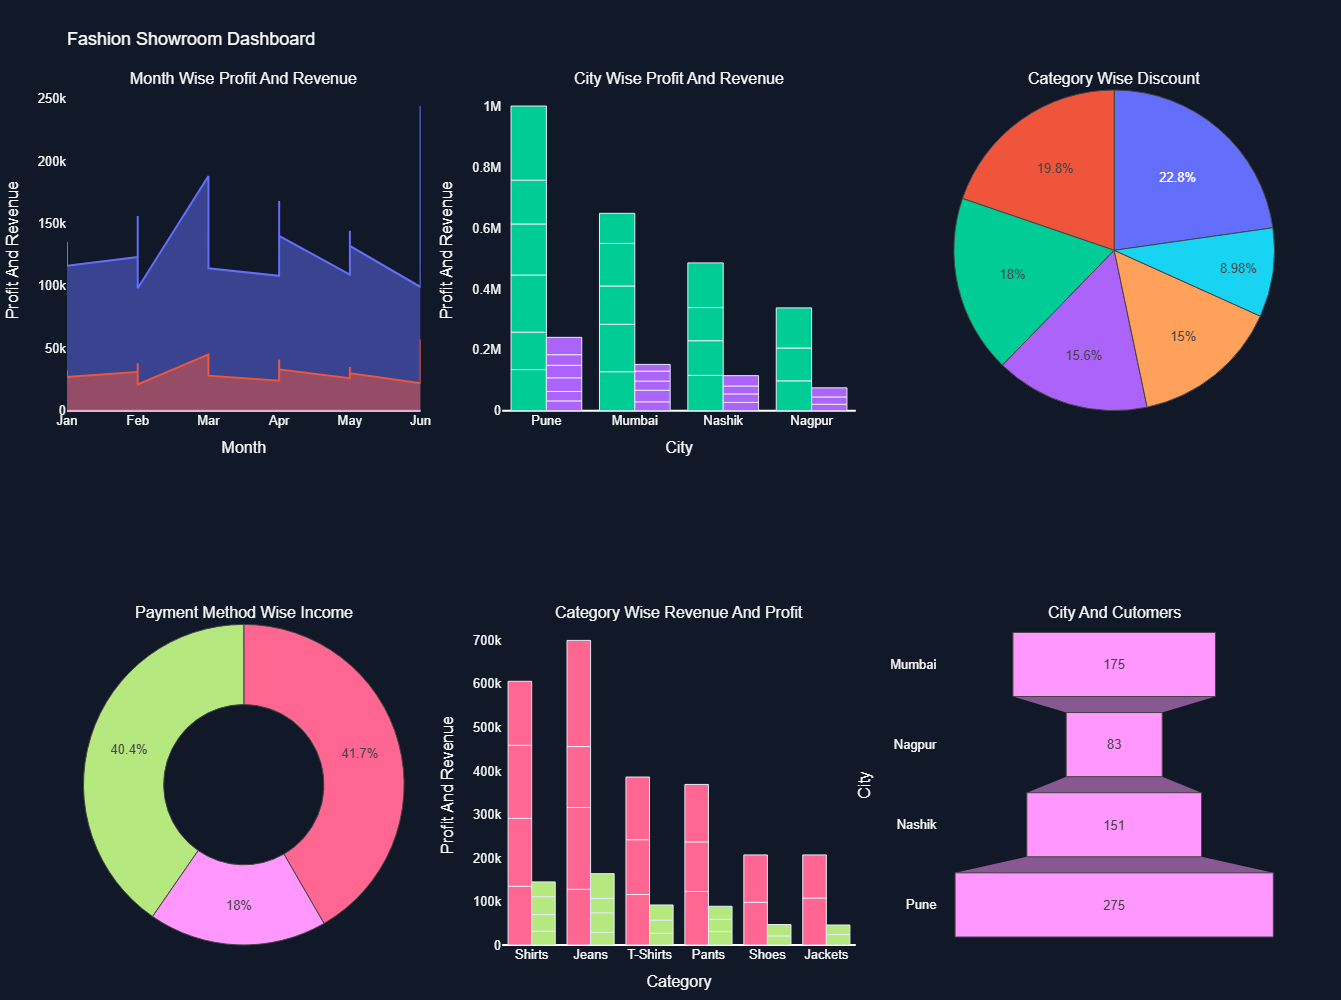

In [19]:
fig = make_subplots(

    rows=2,
    cols=3,

    subplot_titles=(
        "Month Wise Profit And Revenue",
        "City Wise Profit And Revenue",
        "Category Wise Discount",
        "Payment Method Wise Income",
        "Category Wise Revenue And Profit",
        "City And Cutomers"
    ),

    specs=[
        [{"type":"xy"},{"type":"xy"},{"type":"domain"}],
        [{"type":"domain"},{"type":"xy"},{"type":"xy"}]
    ]
)


fig.add_trace(
    go.Scatter(
        x=month,
        y=df1["Revenue"],
        mode="lines",
        fill="tozeroy",
        name="Revenue"
    ),
    row=1,
    col=1
)

fig.add_trace(
    go.Scatter(
        x=month,
        y=df1["Profit"],
        mode="lines",
        fill="tozeroy",
        name="Profit"
    ),
    row=1,
    col=1
)


fig.add_trace(
    go.Bar(
        x=df1["City"],
        y=df1["Revenue"],
        name="City Wise Profit And Revenue"
    ),
    row=1,
    col=2
)


fig.add_trace(
    go.Bar(
        x=df1["City"],
        y=df1["Profit"],
        name="City Wise Profit And Revenue"
    ),
    row=1,
    col=2
)


fig.add_trace(
    go.Pie(
        labels=df1["Category"],
        values=df1["Discount_Percent"],
        name="Category Wise Discount"
    ),
    row=1,
    col=3
)


fig.add_trace(
    go.Pie(
        labels=df1["Payment_Method"],
        values=df1["Revenue"],
        name="Payment Method Wise Income",
        hole=0.5
    ),
    row=2,
    col=1
)


fig.add_trace(
    go.Bar(
        x=df1["Category"],
        y=df1["Revenue"],
        name="Category Wise Revenue And Profit"
    ),
    row=2,
    col=2
)


fig.add_trace(
    go.Bar(
        x=df1["Category"],
        y=df1["Profit"],
        name="Category Wise Revenue And Profit"
    ),
    row=2,
    col=2
)


fig.add_trace(
    go.Funnel(
        y=total_customers.index,
        x=total_customers.values,
        name="City And Customers"
    ),
    row=2,
    col=3
)



fig.update_traces(

    marker=dict(
        line=dict(
            width=1
        )
    )
)


fig.update_xaxes(
    title="City",
    showgrid=False,

    row=1,
    col=2

    
)


fig.update_xaxes(
    title="Month",
    showgrid=False,

    row=1,
    col=1
)


fig.update_xaxes(
    title="Category",
    showgrid=False,

    row=2,
    col=2

    
)


fig.update_xaxes(
    title="Customer",
    showgrid=False,
    
    row=2,
    col=3

    
)


fig.update_yaxes(
    title="Profit And Revenue",
    showgrid=False,

    row=1,
    col=2
)


fig.update_yaxes(
    title="Profit And Revenue",
    showgrid=False,

    row=1,
    col=1
)


fig.update_yaxes(
    title="Profit And Revenue",
    showgrid=False,

    row=2,
    col=2
)


fig.update_yaxes(
    title="City",
    showgrid=False,

    row=2,
    col=3
)



fig.update_layout(

    title="Fashion Showroom Dashboard",

    width=1300,
    height=1000,

    paper_bgcolor="#111827",

    plot_bgcolor="#111827",

    font=dict(
        family="Arial",
        size=13,
        color="#F8FAFC"
    ),

    margin=dict(
        l=50,
        r=50,
        t=90,
        b=50
    ),

    showlegend=False
    
)


In [3]:
df1

,Date,City,Category,Units_Sold,Revenue,Profit,Customers,Discount_Percent,Payment_Method
0,2026-01-05,Pune,Shirts,45,135000,32000,38,5,UPI
1,2026-01-12,Mumbai,Jeans,32,128000,29000,27,10,Card
2,2026-01-20,Nashik,T-Shirts,58,116000,27000,49,8,UPI
3,2026-02-03,Pune,Pants,41,123000,31000,34,5,Cash
4,2026-02-15,Mumbai,Shirts,52,156000,38000,44,12,Card
5,2026-02-25,Nagpur,Shoes,28,98000,21000,25,15,UPI
6,2026-03-05,Pune,Jeans,47,188000,45000,41,7,Card
7,2026-03-18,Mumbai,T-Shirts,63,126000,30000,55,10,UPI
8,2026-03-28,Nashik,Pants,38,114000,28000,32,5,Cash
9,2026-04-07,Nagpur,Jackets,24,108000,24000,21,18,Card
